# Practice Session 02: Data cleaning

After ensuring the dataset has no null values, we would like to do some analysis, which will require some further data cleaning.

Remember that **data cleaning** is a process by which data records are modified or deleted until each record passes data validity criteria.

The analysis will seek to determine if properties in some specific neighbhoods are overpriced or underprices, relative to similar properties of the same size. As proxies for size, we know how many bedrooms, beds, and bathrooms those properties have, and how many of those bathrooms are private or shared.

However, important numerical data is sometimes encoded as text. Moreover, there are some inconsistencies in the data. We will address these.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

⭐ **Regarding the usage of generative AI.** You may use generative AI to (a) understand how to do certain operations, and (b) generate short snippets of code, that you can incorporate into your practice after reviewing them. In that case, add a comment `#AI` before the snippet. You can also add `#AI (edited)` if you edited the code before incorporating it.

⚠️ It is forbidden to use generative AI in these practices for answering the text-based questions.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

Author: <font color="#2680EB">Roger Trilla Piniés</font>

E-mail: <font color="#2680EB">roger.trilla01@eestudiant.upf.edu</font>

AI used: <font color="#2680EB">Google, Gemini</font>

Date: <font color="#2680EB">6/10/2026</font>

In [1]:
# LEAVE AS-IS

# Required libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 0. The dataset

Let us load `listings_clean.csv.gz`, which is **a pre-processed version**. Use the one provided in the ``data/`` directory of the course's GitHub.

Remember that the original dataset was scrapped from the Airbnb site and can be found at [insideairbnb.com](https://insideairbnb.com/get-the-data), and that a [data dictionary](https://docs.google.com/spreadsheets/d/1iWCNJcSutYqpULSQHlNyGInUvHg2BoUGoNRIGa6Szc4/edit?gid=1322284596#gid=1322284596) is available.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [2]:
# LEAVE AS-IS

input_dataset = pd.read_csv("listings_clean.csv.gz", compression="gzip")

# 1. Clean (data about) bathrooms <font color="#2680EB">[20%]</font>

We would like to analyze the data regarding number of bathrooms. This data seems to be found, somewhat redundantly and somewhat inconsistently, in two different columns: `bathrooms` and `bathrooms_text`.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [3]:
# LEAVE AS-IS

def bathroom_crosstab(df):
    crosstab = pd.crosstab(
        df["bathrooms"].fillna("(null)"),
        df["bathrooms_text"].fillna("(null)")
    )
    display(crosstab)
    
bathroom_crosstab(input_dataset)

bathrooms_text,0 baths,0 shared baths,1 bath,1 private bath,1 shared bath,1.5 baths,1.5 shared baths,10 baths,11 baths,12 baths,...,5 baths,5 shared baths,5.5 baths,6 baths,7 baths,8 baths,9 baths,Half-bath,Private half-bath,Shared half-bath
bathrooms,,,,,,,,,,,,,,,,,,,,,
0.0,439,166,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
0.5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12,5,25
1.0,1,0,5122,732,774,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1.5,0,0,0,0,0,397,70,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2.0,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2.5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3.5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


We notice that there is some information on whether bathrooms are **private** or **shared** that is relevant, but is encoded in a text field. First, let us ensure that text field (`bathrooms_text`) is valid according to a constraint. These are the only valid values:

* "0 baths"
* "1 bath"
* "1 private bath"
* "1 shared bath"
* "N baths"
* "N shared baths"

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [4]:
# LEAVE AS-IS
def check_bathrooms_text(df):
    
    # Extract number and text
    # The instructor used AI for the regexp (Claude Sonnet 5)
    extracted = df["bathrooms_text"].str.extract(r"^(\d+(?:\.\d+)?)\s(.*)$")
    extracted_number = extracted[0].astype(float)
    extracted_text = extracted[1]

    # Determine if singular or plural
    is_singular = extracted_text.isin(["bath", "private bath", "shared bath"])
    is_plural = extracted_text.isin(["baths", "private baths", "shared baths"])
    
    # Determine if private, otherwise shared
    is_shared = extracted_text.isin(["shared bath", "shared baths"])
        
    # 
    is_correct = \
        ((extracted_number == 0) & is_plural & ~is_shared) | \
        ((extracted_number == 0.5) & is_plural) | \
        ((extracted_number == 1) & is_singular) | \
        ((extracted_number > 1) & is_plural) 

    invalid_rows = df[~is_correct]
    if len(invalid_rows) > 0:
        print(f"Rows that do not pass the check: {len(invalid_rows)}")
        display(invalid_rows["bathrooms_text"].value_counts().reset_index())
        return False
    else:
        return True

check_bathrooms_text(input_dataset)
    

Rows that do not pass the check: 208


,bathrooms_text,count
0,0 shared baths,166
1,Shared half-bath,25
2,Half-bath,12
3,Private half-bath,5


False

<font size="+1" color="#2680EB">**Implement code to fix bathrooms_text**. Make sure all rows follow the constraint, fix the ones that do not. Do not drop any data. Use the function above that test that your data is now valid in this regard.</font>

In [5]:
def prepare_bathrooms_text(df):
    df = df.copy()
    
    # Canviem les non-standard strings o els errors de text
    df["bathrooms_text"] = df["bathrooms_text"].astype(str).str.strip().str.lower()
    
    # Normalització de patrons coneguts dels datasets d'Airbnb
    df["bathrooms_text"] = df["bathrooms_text"].replace({
        "half-bath": "0.5 baths",
        "shared half-bath": "0.5 shared baths",
        "private half-bath": "0.5 private baths",
        "1 half-bath": "0.5 baths",
        "1 shared half-bath": "0.5 shared baths",
        "1 private half-bath": "0.5 private baths"
    })
    
    # Corregir el singular/plural i formats estàndard
    def fix_format(text):
        if text == "nan" or pd.isna(text):
            return "1 bath"
        
        # Extreure el número i la descripció del text
        extracted = pd.Series([text]).str.extract(r"^(\d+(?:\.\d+)?)\s*(.*)$")
        if extracted.isnull().values.any():
            return "1 bath"
            
        num = float(extracted[0][0])
        desc = extracted[1][0].strip()
        
        is_shared = "shared" in desc
        is_private = "private" in desc
        
        if num == 0:
            return "0 baths"
        elif num == 0.5:
            if is_shared:
                return "0.5 shared baths"
            elif is_private:
                return "0.5 private baths"
            return "0.5 baths"
        elif num == 1:
            if is_shared:
                return "1 shared bath"
            elif is_private:
                return "1 private bath"
            return "1 bath"
        else:
            num_str = f"{num:g}"
            if is_shared:
                return f"{num_str} shared baths"
            elif is_private:
                return f"{num_str} private baths"
            return f"{num_str} baths"

    df["bathrooms_text"] = df["bathrooms_text"].apply(fix_format)
    return df

df2 = prepare_bathrooms_text(input_dataset)
check_bathrooms_text(df2)

True

The information on whether bathrooms are **private** or **shared** is relevant, but is encoded in a text field. Let us expand it as follows:

1. `bathrooms` should contain the number of bathrooms. If this is incompatible with the `bathrooms_text`, we drop the row.
2. A new column, `bathrooms_type` should include the type as `private` or `shared` according to `bathrooms_text`. If this is unspecified, we will assume it is private.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="#2680EB">**Implement the code to prepare data about bathrooms**. Print the number of rows that were dropped</font>

In [6]:
def prepare_data_bathrooms(df):
    df = df.copy()
    original_len = len(df)
    
    # Extreure el nombre de banys del text
    number_in_bathrooms_text = df["bathrooms_text"].str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)
    
    # Descomptar o eliminar les files on `bathrooms` i `bathrooms_text` no són compatibles
    incompatible_mask = df["bathrooms"].notna() & (df["bathrooms"] != number_in_bathrooms_text)
    df = df[~incompatible_mask].copy()
    
    # Omplir valors nuls de `bathrooms` amb el número extret de `bathrooms_text`
    df["bathrooms"] = df["bathrooms"].fillna(number_in_bathrooms_text)
    
    # Bany és shared o private
    df["bathrooms_type"] = np.where(df["bathrooms_text"].str.contains("shared", case=False, na=False), "shared", "private")
    
    modified_len = len(df)
    print(f"Original: {original_len}, new: {modified_len}, dropped: {original_len - modified_len}")
    return df

df3 = prepare_data_bathrooms(df2)
display(df3[["bathrooms", "bathrooms_text", "bathrooms_type"]].drop_duplicates().sort_values("bathrooms"))

Original: 11482, new: 11479, dropped: 3


,bathrooms,bathrooms_text,bathrooms_type
36,0.0,0 baths,private
850,0.5,0.5 baths,private
1388,0.5,0.5 shared baths,shared
9731,0.5,0.5 private baths,private
109,1.0,1 private bath,private
3,1.0,1 bath,private
14,1.0,1 shared bath,shared
5,1.5,1.5 baths,private
113,1.5,1.5 shared baths,shared
1083,2.0,2 shared baths,shared


Now we can analyze this data, for instance by comparing histograms.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

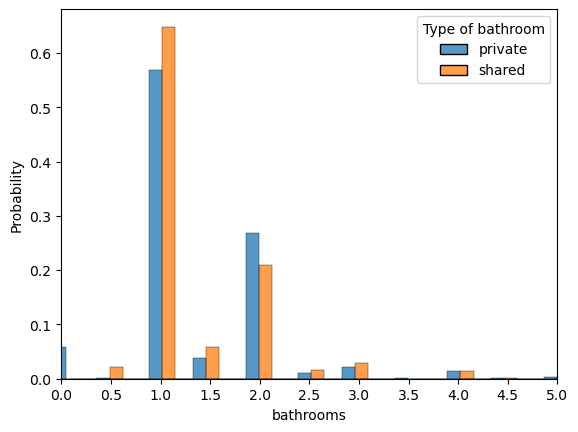

In [7]:
# LEAVE AS-IS

ax = sns.histplot(data=df3, x="bathrooms", 
                  stat="probability", common_norm=False,
                  hue="bathrooms_type", multiple="dodge", shrink=3)
ax.legend_.set_title("Type of bathroom")
plt.xticks(np.arange(0, 5.5, 0.5))
_ = plt.xlim(0, 5)

<font size="+1" color="#2680EB">**Describe what you see in the histogram above**.</font>

**Answer: According to the histogram above:**

El primer que podem veure és que clarament, tant en el cas dels privats com dels compartits, la probabilitat més alta és que hi hagi 1 bany. En ambdós casos supera el 50% d'opcions i, fins i tot passa del 60% en el cas dels compartits.

Podem veure que el segon valor més freqüent és el dels 2 banys, on els privats superen per no gaire als compartits, on els dos volten una mica per sobre del 20%.

Es pot veure que també apareixen banys no enters, tot i que en menor freqüència. Podem veure els 1.5 banys i els 2.5, però el seu percentatge és exageradament petit comparat amb l'1 o els 2 banys.

Per últim, podem veure com tenim valors residuals als 0 banys privats o als 3, 3.5, 4, 4.5 i 5 banys.

# 2. Fix inconsistencies in bedrooms and beds <font color="#2680EB">[20%]</font>

Let us now look at the number of bedrooms and beds.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [8]:
# LEAVE AS-IS

def bedrooms_crosstab(df):
    crosstab = pd.crosstab(
        df["bedrooms"].fillna("(null)"),
        df["beds"].fillna("(null)")
    )
    display(crosstab)
    
bedrooms_crosstab(df3)

beds,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,24.0,25.0,26.0,30.0,31.0,32.0,33.0,35.0,37.0,127.0
bedrooms,,,,,,,,,,,,,,,,,,,,,
0.0,78,655,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1.0,0,2595,1046,202,58,7,12,3,10,0,...,0,0,1,0,0,0,0,0,0,0
2.0,0,52,1527,1348,500,109,7,4,2,1,...,0,0,0,0,0,0,0,0,0,1
3.0,0,12,14,755,723,412,210,57,5,3,...,0,0,0,0,0,0,0,0,0,0
4.0,0,6,2,2,231,134,138,94,35,10,...,0,0,0,0,0,0,0,0,0,0
5.0,0,1,0,0,1,29,29,32,22,13,...,0,0,0,0,0,0,0,0,0,0
6.0,0,1,0,0,0,0,13,10,10,21,...,1,0,0,0,0,0,0,0,0,0
7.0,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
8.0,0,0,0,0,0,0,0,0,5,1,...,0,0,0,0,0,0,0,0,0,0


<font size="+1" color="#2680EB">**Describe the inconsistencies that can be observed in this matrix**. Answer the following questions.</font>

**Answer:**

**In terms of bedrooms and beds, what does it mean in this case that most large values can be found near the diagonal?**

Vol dir que la dada té sentit: la majoria de pisos tenen una quantitat de llits lògica segons les habitacions que tenen (per exemple, 1 habitació i 1-2 llits, o 2 habitacions i 2-3 llits).**

**Do you see any gross inconsistency between the number of bedrooms and beds in some cases? Can you give an example of such inconsistency?**

Sí, es veuen errades molt grans a la taula. Per exemple:

Pisos amb 2 habitacions i 127 llits.

Pisos amb 29 habitacions i només 1 llit.

**Assume that the number of beds is always correct, but that the number of bedrooms could have been miscounted. What validity criteria would you apply over the number of bedrooms, and what would you do in cases of violation of each criteria? For each validity criteria, indicate whether you will *fix* the data and how, or whether you will *drop* the row.**

A property with 0 beds should have 0 bedrooms: Si té 0 llits i més de 0 habitacions, ho arreglem posant les habitacions a 0 (bedrooms = 0).

A property with beds > 0 cannot have more bedrooms than beds (bedrooms > beds): Un pis no pot tenir més habitacions que llits totals. Si passa això (per exemple, 4 habitacions i 1 llit), eliminem la fila (drop) perquè és una dada mal introduïda.

**We will drop invalid rows in the data, but this may entail dropping some special cases that are actually correct.  Which correct cases do you think your rules may erroneously discard?**

Habitacions de la casa que no són per dormir (com un despatx, una sala d'estar o un vestidor).

To check validity of rows in a dataframe using a complex validation, you can use code like this:

* `valid1 = df["col1"] > 0`
* `valid2 = df["col2"] < 0`
* ...
* `invalid_rows = df[~(valid1 & valid2 & ...)]`

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="#2680EB">**Implement a check for your validy criteria**. Print the combinations of beds and bedrooms that fail the criteria.</font>

In [9]:
def check_bedrooms_beds(df):
    # Si no hi ha llits (beds == 0), no hi hauria d'haver habitacions (bedrooms == 0).
    # El nombre d'habitacions no pot superar significativament el nombre de llits (bedrooms <= beds).
    
    valid1 = (df["beds"] == 0) & (df["bedrooms"] == 0)
    valid2 = (df["beds"] > 0) & (df["bedrooms"] <= df["beds"])
    
    is_valid = valid1 | valid2
    invalid_rows = df[~is_valid]
    
    if len(invalid_rows) > 0:
        print(f"Invalid rows: {len(invalid_rows)}")
        display(invalid_rows.groupby(["bedrooms", "beds"]).size().reset_index(name="count"))
        return False
    else:
        return True

check_bedrooms_beds(df3)

Invalid rows: 100


,bedrooms,beds,count
0,2.0,1.0,52
1,3.0,1.0,12
2,3.0,2.0,14
3,4.0,1.0,6
4,4.0,2.0,2
5,4.0,3.0,2
6,5.0,1.0,1
7,5.0,4.0,1
8,6.0,1.0,1
9,9.0,1.0,2


False

<font size="+1" color="#2680EB">**Implement data cleaning to ensure the validy criteria**. You can fix data or drop rows. If you drop rows, indicate how many did you drop.</font>

In [10]:
def fix_bedrooms_bed(df):
    df = df.copy()
    original_len = len(df)
    
    # Correcció: Si beds == 0, establim bedrooms = 0
    df.loc[df["beds"] == 0, "bedrooms"] = 0
    
    # Eliminació de files on el nombre d'habitacions sigui estrictament major que el nombre de llits quan beds > 0
    invalid_mask = (df["beds"] > 0) & (df["bedrooms"] > df["beds"])
    df = df[~invalid_mask].copy()
    
    dropped = original_len - len(df)
    print(f"Rows dropped during bedroom/beds cleaning: {dropped}")
    return df

df4 = fix_bedrooms_bed(df3)
check_bedrooms_beds(df4)

Rows dropped during bedroom/beds cleaning: 100


True

Now we can analyze this data, for instance by creating a heatmap of `bedrooms` and `beds`.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<Axes: xlabel='beds', ylabel='bedrooms'>

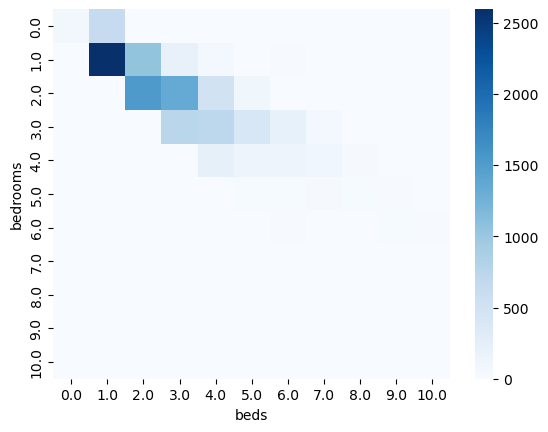

In [11]:
# LEAVE AS-IS

# The instructor used AI to understand crosstab filtering and Seaborn parameters (Claude Sonnet 5)
crosstab = pd.crosstab(df4["bedrooms"], df4["beds"])
crosstab = crosstab.loc[crosstab.index <= 10, crosstab.columns <= 10]
sns.heatmap(crosstab, cmap="Blues")

# 3. Categorize properties by size <font color="#2680EB">[10%]</font>

We will group properties into categories by size. We will do it by using the data that we have on beds, bedrooms, and bathrooms.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

## 3.1. Fix fractional bathrooms

For this analysis, we will consider that half a bathroom does not count, so we will convert 0.5 to 0, 1.5 to 1, and so on. To compute the floor of a number, one option is to use the `//` operator in Python, which divides and drop the remainder.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="#2680EB">**Implement code to convert the number of bathrooms**. Compute the floor of the number of bathrooms.</font>

In [12]:
def remove_fractional_bathrooms(df):
    df = df.copy()
    # Aplicar la divisió sencera per eliminar la meitat de bany (truncar decimal)
    df["bathrooms"] = df["bathrooms"] // 1
    return df

df5 = remove_fractional_bathrooms(df4)

Let us look at a heatmap between `beds` and `bathrooms`.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<Axes: xlabel='bathrooms', ylabel='beds'>

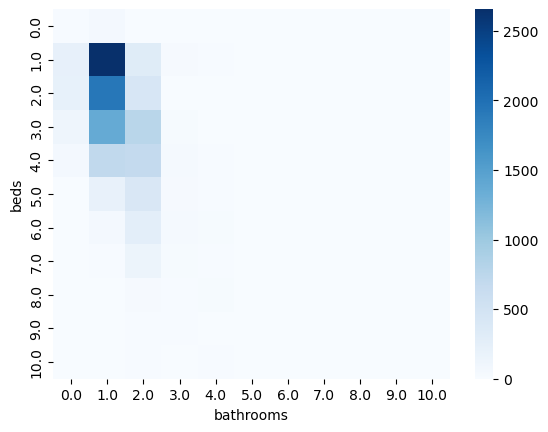

In [13]:
# LEAVE AS-IS

# The instructor used AI for crosstab filtering and Seaborn parameters (Claude Sonnet 5)
crosstab = pd.crosstab(df5["beds"], df5["bathrooms"])
crosstab = crosstab.loc[crosstab.index <= 10, crosstab.columns <= 10]
sns.heatmap(crosstab, cmap="Blues")

In the heatmap above, we can see that properties having 3 or 4 beds may have a second bathroom, and that properties having 5 beds or more are more likely to have a second bathroom than to have a single bathroom.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

## 3.2. Create categories by size

We will now do a categorization. One category will be properties having a single bed, we will call this category "S" (for small). Then, we will have a medium category ("M"), a large category ("L"), and an extra large category ("XL").

Pandas allows for the creation of "ordinal" data types using `CategoricalDtype`, as we use in the code below.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="#2680EB">**Add a column "category" to the properties**. This can be "S", "M", "L", or "XL", and can depend on the number of beds, bedrooms, and/or bathrooms. Make sure that each category contains at least 500 properties.</font>

In [14]:
def add_category(df):
    df = df.copy()
    
    df["category"] = None
    
    # Definim les condicions
    small = (df["beds"] == 1)
    medium = (df["beds"] == 2) | ((df["beds"] >= 3) & (df["bedrooms"] <= 1))
    large = ((df["beds"] >= 3) & (df["beds"] <= 4) & (df["bedrooms"] >= 2)) | ((df["beds"] == 5) & (df["bathrooms"] <= 1))
    xlarge = (df["beds"] >= 5) & (df["bathrooms"] >= 2) | (df["beds"] >= 6)
    
    # Assignem les categories de text
    df.loc[small, "category"] = "S"
    df.loc[medium, "category"] = "M"
    df.loc[large, "category"] = "L"
    df.loc[xlarge, "category"] = "XL"
    
    # Per a qualsevol fila restant sense assignar
    df["category"] = df["category"].fillna("M")

    # Convertim la columna a ordinal
    size_ordinal = pd.CategoricalDtype(categories=["S", "M", "L", "XL"], ordered=True)
    df["category"] = df["category"].astype(size_ordinal)
    
    return df

df6 = add_category(df5)
display(df6.groupby(["category"], observed=True).size().reset_index(name="count"))

,category,count
0,S,3250
1,M,2911
2,L,3772
3,XL,1446


# 4. Analyze property size per neighborhood <font color="#2680EB">[10%]</font>

Now we will look at property sizes per area (`neibourhood_group_cleansed` in the dataset) and per neighborhood.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

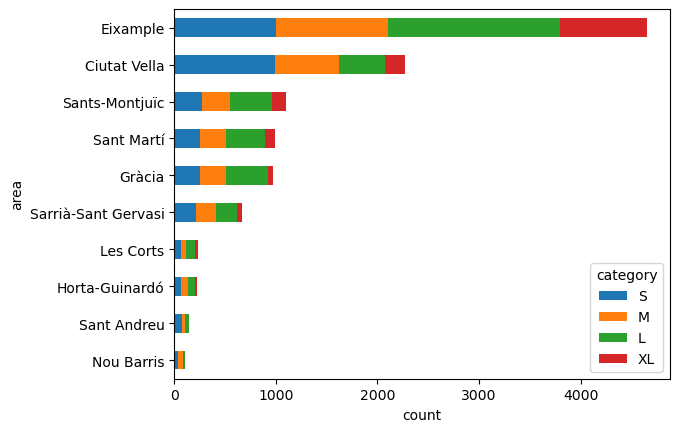

In [15]:
# LEAVE AS-IS

crosstab = pd.crosstab(df6["neighbourhood_group_cleansed"], df6["category"])
crosstab = crosstab.loc[crosstab.sum(axis=1).sort_values().index]
# The instructor used AI for stacked plot (Claude Sonnet 5)
crosstab.plot(kind="barh", stacked=True)
plt.xlabel("count")
_ = plt.ylabel("area")

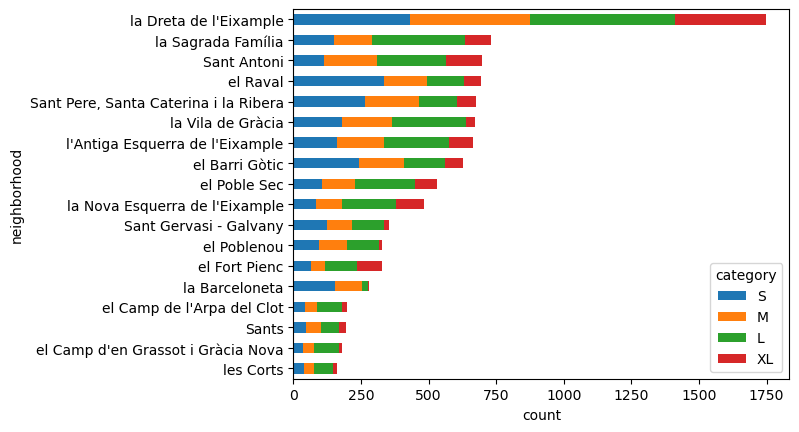

In [16]:
# LEAVE AS-IS

crosstab = pd.crosstab(df6["neighbourhood_cleansed"], df6["category"])
crosstab = crosstab[crosstab.sum(axis=1) >= 150]  # Only neighborhoods with at least this many properties
crosstab = crosstab.loc[crosstab.sum(axis=1).sort_values().index]
crosstab.plot(kind="barh", stacked=True)
plt.xlabel("count")
_ = plt.ylabel("neighborhood")


<font size="+1" color="#2680EB">**Describe what you see in the plots above**.</font>

**Answer:**

**What do you observe regarding the areas and neighborhoods that concentrate the larger number of listings?**

En el primer gràfic es veu clarament que l'Eixample i Ciutat Vella destaquen molt per sobre de la resta en quantitat total de propietats, ja que són barris cèntrics i turístics. En el segon gràfic, barris com la Dreta de l'Eixample, la Sagrada Família, Sant Antoni o el Raval són els que acumulen més anuncis, per la mateixa raó que al primer gràfic.

**What do you observe regarding the proportion of different property sizes per neighborhood?**

A la majoria de barris centrals i de la costa, com el Raval, el Barri Gòtic o la Barceloneta, les propietats S representen la major part de l'oferta. Veiem que les propietats L i XL són en zones concretes i tenen un pes molt més important en barris com la Dreta de l'Eixample, la Sagrada Família o Sant Antoni, mentre que en barris més densos com la Barceloneta quasi no n'hi ha.

# 5. Group property types <font color="#2680EB">[10%]</font>

As you can see next, there are more than 40 property types described in the column `property_type`. Add a new column `property_type_group` in which you group property types as follows:

* Rooms in an apartment, hostel, hotel, etc. = `room`
* Entire apartments, homes, lofts, condos, etc. = `unit`

Other, including campers, boats, etc., should be dropped.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [17]:
# LEAVE AS-IS

# The instructor used AI (Claude Sonnet 5)
display(df6.groupby(["property_type"], observed=True)
        .size().reset_index(name="count")
        .sort_values("count", ascending=False))


,property_type,count
11,Entire rental unit,8250
26,Private room in rental unit,1333
12,Entire serviced apartment,327
34,Room in hotel,257
4,Entire condo,249
24,Private room in hostel,195
9,Entire loft,144
32,Room in boutique hotel,103
23,Private room in home,100
7,Entire home,68


<font size="+1" color="#2680EB">**Add a column "property_type_group"**. Use the specification above.</font>

In [18]:
#AI, m'ha ajudat en aquest codi, ja que m'havia quedat encallat i, no sabia com extreure les categories especials.

def add_property_type_group(df):
    df = df.copy()
    
    # Definir patrons de cerca per a habitacions vs unitats meves
    room_keywords = "room|hostel|hotel|shared|private room"
    
    is_room = df["property_type"].str.contains(room_keywords, case=False, na=False)
    
    # Filtrem habitacions (room) i habitatges complets (unit)
    df["property_type_group"] = np.where(is_room, "room", "unit")
    
    # Excloure categories especials
    other_types = ["Camper/RV", "Boat", "Houseboat", "Tent", "Yurt", "Cavan", "Treehouse"]
    df = df[~df["property_type"].isin(other_types)].copy()
    
    return df

df7 = add_property_type_group(df6)
display(df7.groupby(["property_type", "property_type_group"], observed=True)
        .size().reset_index(name="count")
        .sort_values(["property_type_group", "count"], ascending=False))

,property_type,property_type_group,count
9,Entire rental unit,unit,8250
10,Entire serviced apartment,unit,327
2,Entire condo,unit,249
7,Entire loft,unit,144
5,Entire home,unit,68
11,Entire townhouse,unit,19
12,Entire vacation home,unit,18
3,Entire guest suite,unit,9
13,Entire villa,unit,6
42,Tiny home,unit,5


We can now look at the distribution per area (what the original dataset calls "neighborhood groups").

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

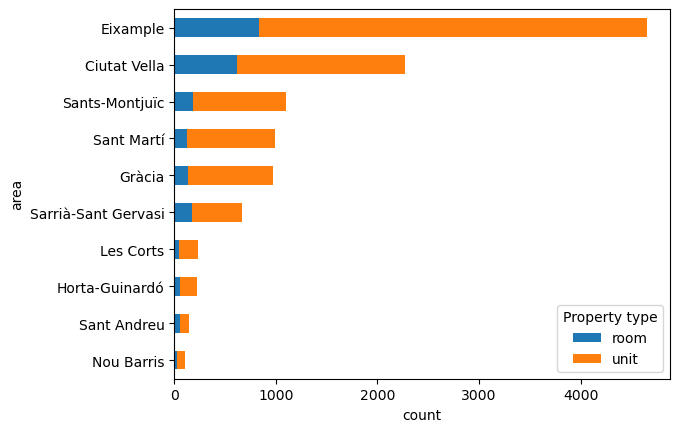

In [19]:
# LEAVE AS-IS

crosstab = pd.crosstab(df7["neighbourhood_group_cleansed"],
                       df7["property_type_group"])
crosstab = crosstab.loc[crosstab.sum(axis=1).sort_values().index]
ax = crosstab.plot(kind="barh", stacked=True)
ax.legend_.set_title("Property type")
plt.xlabel("count")
_ = plt.ylabel("area")

<font size="+1" color="#2680EB">**Describe what you see in the plot above**.</font>

**Answer:**

**What do you observe regarding the property types per area?**

Es pot veure clarament com la gran majoria de propietats són pisos. Hi ha àrees com l'Eixample que superen els 3000 pisos i, tenen gairebé 1000 habitacions disponibles. A Ciutat Vella podem veure que és la zona on més percentatge d'habitacions (room) hi ha en comparació en l'oferta total que hi tenim en aquella zona. 

La resta d'àrees, tenen molt més percentatge de pisos en oferta que no pas habitacions individuals. Per últim també es pot destacar que a Nou Barris, no hi ha pràcticament habitacions individuals. Això, es deu a que zones com l'Eixample o Ciutat Vella, concentren més estudiants i joves.

# 6. Convert price to a numerical value <font color="#2680EB">[10%]</font>

Convert "price" to a numerical value. It is currently expressed as a string with a dollar sign and thousands separators.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="#2680EB">**Write code to convert the column price to a numerical value**.</font>

In [20]:
def convert_price_to_numeric(df):
    df = df.copy()
    
    # Treure el signe de dòlar, les comes i convertir a float
    if df["price"].dtype == object:
        df["price"] = df["price"].str.replace("$", "", regex=False)
        df["price"] = df["price"].str.replace(",", "", regex=False)
        df["price"] = df["price"].astype(float)
        
    return df

df8 = convert_price_to_numeric(df7)

The following shows you the distribution of price (per night, in USD) per area.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

Text(0, 0.5, 'neighborhood')

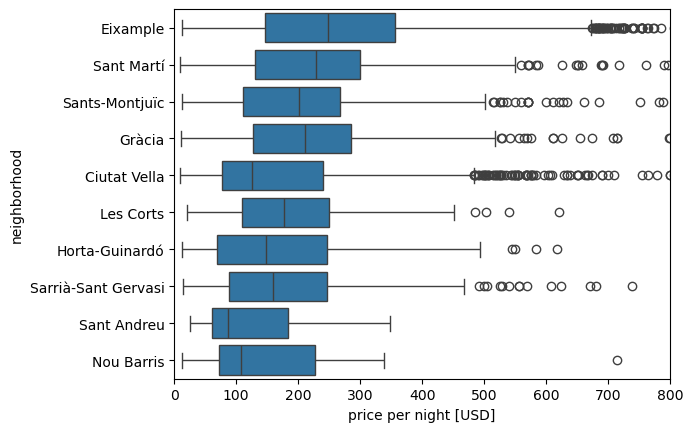

In [21]:
# LEAVE AS-IS

order = df8.groupby("neighbourhood_group_cleansed")["price"].mean().sort_values(ascending=False).index
sns.boxplot(data=df8, y="neighbourhood_group_cleansed", x="price", order=order)

plt.xlim(0, 800)
plt.xlabel("price per night [USD]")
plt.ylabel("neighborhood")

# 7. Analyze price and property size per area <font color="#2680EB">[20%]</font>

Next, perform an analysis of price per property size and area. For the purposes of this analysis, focus on entire units, discarding rooms.

The question we are trying to answer is: to what extent are average rental prices per neighborhood dependent on the fact that there is a larger proportion of large units in that neighborhood?

The following plot inspires this analysis: notice, for instance, that "large" units (category "L") have similar price distributions across several areas of the city. Perhaps what we see above, that some neighborhoods are more expensive than others, could be solely because they have a bigger proportion of large units.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

Text(0, 0.5, 'neighborhood')

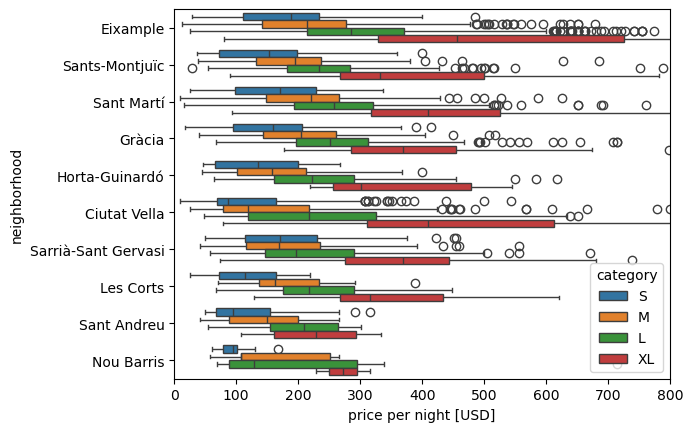

In [22]:
# LEAVE AS-IS

df9 = df8[df8["property_type_group"] == "unit"]

order = df9.groupby("neighbourhood_group_cleansed")["price"].mean().sort_values(ascending=False).index
# The instructor used AI for boxplot parameters (Claude Sonnet 5)
sns.boxplot(data=df9,
            y="neighbourhood_group_cleansed",
            x="price",
            hue="category",
            order=order)

plt.xlim(0, 800)
plt.xlabel("price per night [USD]")
plt.ylabel("neighborhood")

## 7.1. Relative price

We will first tackle this question by computing a *relative price*, that will indicate for each property, the ratio between its price and the average price of an apartment of that size.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="#2680EB">**Implement a computation of relative price**. First, compute the average price per size (S/M/L/XL), then, create the column *relative_price* as price/average price.</font>

In [23]:
def add_relative_price(df):
    df = df.copy()
    
    # Calcular el preu mitjà per mida a nivell global
    avg_price_per_size = df.groupby("category", observed=True)["price"].transform("mean")
    
    # Crear la columna price_relative
    df["price_relative"] = df["price"] / avg_price_per_size
    return df

df10 = add_relative_price(df9)
display(df10.groupby("neighbourhood_group_cleansed")["price_relative"].mean().reset_index().sort_values("price_relative", ascending=False))

,neighbourhood_group_cleansed,price_relative
1,Eixample,1.134044
7,Sant Martí,1.007505
2,Gràcia,0.972531
8,Sants-Montjuïc,0.917908
9,Sarrià-Sant Gervasi,0.885834
3,Horta-Guinardó,0.851389
0,Ciutat Vella,0.839350
6,Sant Andreu,0.827878
4,Les Corts,0.796971
5,Nou Barris,0.762056


<font size="+1" color="#2680EB">**Write your observations on this relative price result**. 
</font>

**Answer:**

**What do you observe regarding relative price?**

L'Eixample i Sant Martí són els únics districtes on els preus són més cars que la mitjana global de la ciutat per a propietats de la mateixa mida. Podem veure que l'Eixample té un preu relatiu significativament superior a la resta, un 13% per sobre de la mitjana. 

La majoria de districtes tenen un preu relatiu inferior a 1: Districtes com Ciutat Vella, Les Corts o Nou Barris tenen preus per sota de la mitjana ajustada per la mida de la propietat.

## 7.2. Size-adjusted average price

Next we will compute a size-adjusted average price. This is the average price in an area, if we were to replace all prices for a unit by the city-wide average price for a unit of that size.

For instance, suppose that there were two sizes A and B, and the average price for A is X, while the average price for B is Y. Suppose that in an area there are M apartments of size A and N apartments of size B. The size-adjusted average price for that area would be (M*X + N*Y)/(M+N).

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="#2680EB">**Implement a computation of size-adjusted price**. First, compute the average price per size (S/M/L/XL), then, compute a size-adjusted relative price. The output should be a dataframe with columns "neighbourhood_group_cleansed" and "size_adjusted_avg_price".</font>

In [24]:
def compute_size_adjusted_price(df):
    # Preu mitjà global per cada categoria de mida
    avg_price_per_category = df.groupby("category", observed=True)["price"].mean()
    
    # Per a cada barri/districte, comptem quantes propietats té de cada categoria
    counts = df.groupby(["neighbourhood_group_cleansed", "category"], observed=True).size().unstack(fill_value=0)
    
    # Calculem el preu ajustat per mida segons la fórmula: sum(M_i * X_i) / sum(M_i)
    weighted_prices = counts.dot(avg_price_per_category)
    total_properties = counts.sum(axis=1)
    
    size_adjusted_price = (weighted_prices / total_properties).to_frame(name="size_adjusted_avg_price")
    return size_adjusted_price

size_adjusted_price = compute_size_adjusted_price(df10)
display(size_adjusted_price.reset_index().sort_values(["size_adjusted_avg_price"], ascending=False))

,neighbourhood_group_cleansed,size_adjusted_avg_price
1,Eixample,330.480269
8,Sants-Montjuïc,296.708038
4,Les Corts,290.580634
3,Horta-Guinardó,278.683927
7,Sant Martí,278.620469
9,Sarrià-Sant Gervasi,268.495100
0,Ciutat Vella,261.276747
2,Gràcia,258.828334
6,Sant Andreu,236.354641
5,Nou Barris,219.176319


<font size="+1" color="#2680EB">**Write your observations on this size-adjusted average price result**.
</font>

**Answer:**

**What do you observe regarding size-adjusted average price?**

L'Eixample té el preu mitjà ajustat per mida més alt de tota la ciutat, ronda els 330,55 €. 

Si mirem la grandària esperada dels pisos per districte, ens mostra quin seria el preu mitjà d'un districte si apliquéssim els preus generals de la ciutat. Districtes com Sants-Montjuïc o Les Corts tenen valors alts perquè tendeixen a tenir pisos de mides més grans en promig.

Nou Barris i Sant Andreu són els més econòmics ja que tenen els valors més baixos, perque hi predominen habitatges de mides més petites.

**Comparing the results you obtain using the relative price, is there any robust conclusion you can reach?**

La ubicació té un pes decisiu en el preu, quan un districte té un preu relatiu alt, ens confirma que l'habitatge serà més car independentment de la seva mida.

La mida pot enganyar a la percepció del preu. Hi ha districtes com Les Corts que tenen un preu ajustat alt per la mida dels seus pisos, però un preu relatiu més baix, el que significa que la seva mida fa que semblin més cars del que realment són.

**What are all the limitations of this analysis? Name at least three.**

Agrupació de mides molt ampla. Classificar els pisos en només 4 categories generals fa que es perdi molta precisió respecte al nombre exacte de metres quadrats o habitacions.

No té en compte l'estat o la qualitat de l'habitatge. No considera l'edat del pis o si està reformat, si té terrassa, ascensor, aire condicionat o vistes.

Barreja diferents tipus d'allotjament. Tracta per igual els lloguers turístics de pocs dies i els lloguers de temporada o de més llarga durada, que tenen preus molt diferents.

# DELIVER (individually)

Remember to read the section on "delivering your code" in the [course evaluation guidelines](https://github.com/chatox/data-mining-course/blob/master/upf/upf-evaluation.md).

Deliver this notebook, renamed as `PSxx_Unnnnnn_YourName.ipynb` where:
* *PSxx* is the practice number.
* *Unnnnnn* is your UPF id number.
* *YourName* is your name.

## Extra points available

For more learning and extra points, let us ignore categorical sizes and instead compute a bed-adjusted price for each rental. First, compute the average price per bed across the entire city. Then, compare the actual price of a property with its price if we were charging per bed the average. 

**Note:** if you go for the extra points, add an additional section ``# <font color="#2680EB">Additional results: bed-adjusted analysis</font>`` at the end of your notebook.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+2" color="#00A365">I hereby declare that I completed this practice myself, that I have not copied it from others, or from external sources without citing them, and that I have followed the generative AI instructions stated above.</font>